# Análise Exploratória de Dados (EDA) - Churn de Clientes
O objetivo deste notebook é explorar a base de dados de telecomunicações para identificar os principais fatores que levam os clientes ao cancelamento do serviço (*Churn*).


In [3]:
%pip install pandas numpy seaborn matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Configura o Seaborn para gráficos visualmente mais agradáveis
sns.set_theme(style="whitegrid")
# Garante que os gráficos apareçam diretamente no notebook
%matplotlib inline 

In [5]:
# Arquivo que iremos ler

DATA_PATH = Path("../data/raw/Telco_customer_churn.csv")

df = pd.read_csv(DATA_PATH, sep = ";")
# Exibe o formato (linhas, colunas) e as primeiras 5 linhas
print(f"O dataset possui {df.shape[0]} linhas e {df.shape[1]} colunas.\n")
df.head()


O dataset possui 7043 linhas e 33 colunas.



,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783","33,964131","-118,272783",Male,...,Month-to-month,Yes,Mailed check,"53,85","108,15",Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742","34,059281","-118,307420",Female,...,Month-to-month,Yes,Electronic check,"70,7","151,65",Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953","34,048013","-118,293953",Female,...,Month-to-month,Yes,Electronic check,"99,65","820,5",Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709","34,062125","-118,315709",Female,...,Month-to-month,Yes,Electronic check,"104,8","3046,05",Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293","34,039224","-118,266293",Male,...,Month-to-month,Yes,Bank transfer (automatic),"103,7","5036,3",Yes,1,89,5340,Competitor had better devices


In [6]:
# Informações sobre colunas, tipos de dados e valores ausentes
df.info()

# Caso queira ver a contagem exata de nulos por coluna
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         7043 non-null   str  
 1   Count              7043 non-null   int64
 2   Country            7043 non-null   str  
 3   State              7043 non-null   str  
 4   City               7043 non-null   str  
 5   Zip Code           7043 non-null   int64
 6   Lat Long           7043 non-null   str  
 7   Latitude           7043 non-null   str  
 8   Longitude          7043 non-null   str  
 9   Gender             7043 non-null   str  
 10  Senior Citizen     7043 non-null   str  
 11  Partner            7043 non-null   str  
 12  Dependents         7043 non-null   str  
 13  Tenure Months      7043 non-null   int64
 14  Phone Service      7043 non-null   str  
 15  Multiple Lines     7043 non-null   str  
 16  Internet Service   7043 non-null   str  
 17  Online Security    7043 n

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [7]:
# Se a coluna ainda for do tipo texto/object, aplica a limpeza
if df['Total Charges'].dtype == 'object':
    print("Tratando espaços em branco ocultos na coluna Total Charges...")
    # Remove espaços e força conversão para número
    df['Total Charges'] = pd.to_numeric(df['Total Charges'].str.strip(), errors='coerce')
    # Preenche clientes novos (tenure = 0) com 0.0
    df['Total Charges'] = df['Total Charges'].fillna(0.0)

if df['Monthly Charges'].dtype == 'object':
    print("Tratando espaços em branco ocultos na coluna Monthly Charges...")
    # Remove espaços e força conversão para número
    df['Monthly Charges'] = pd.to_numeric(df['Monthly Charges'].str.strip(), errors='coerce')
    # Preenche clientes novos (tenure = 0) com 0.0
    df['Monthly Charges'] = df['Monthly Charges'].fillna(0.0)

# 1. Substitui a vírgula por ponto (caso exista) e converte para número (float)
df['Monthly Charges'] = df['Monthly Charges'].astype(str).str.replace(',', '.')
df['Monthly Charges'] = pd.to_numeric(df['Monthly Charges'], errors='coerce')

# 2. Faz o mesmo com a coluna Total Charges para evitar que aconteça o mesmo erro depois
df['Total Charges'] = df['Total Charges'].astype(str).str.replace(',', '.')
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

# 3. Verifica se agora elas são exibidas como float64
print(df[['Monthly Charges', 'Total Charges']].dtypes)



Monthly Charges    float64
Total Charges      float64
dtype: object


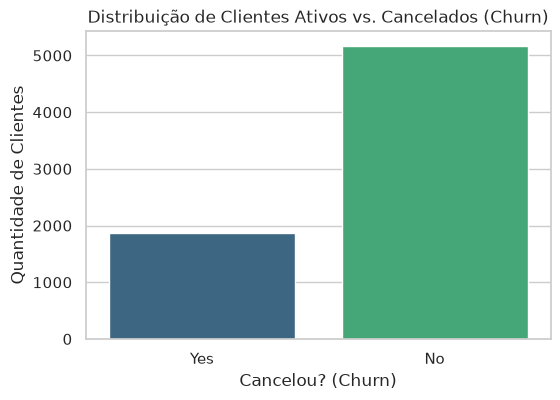

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn Label', hue='Churn Label', legend=False, palette='viridis')
plt.title('Distribuição de Clientes Ativos vs. Cancelados (Churn)')
plt.xlabel('Cancelou? (Churn)')
plt.ylabel('Quantidade de Clientes')
plt.show()

# Exibe a porcentagem exata
print(df['Churn Label'].value_counts(normalize=True) * 100)


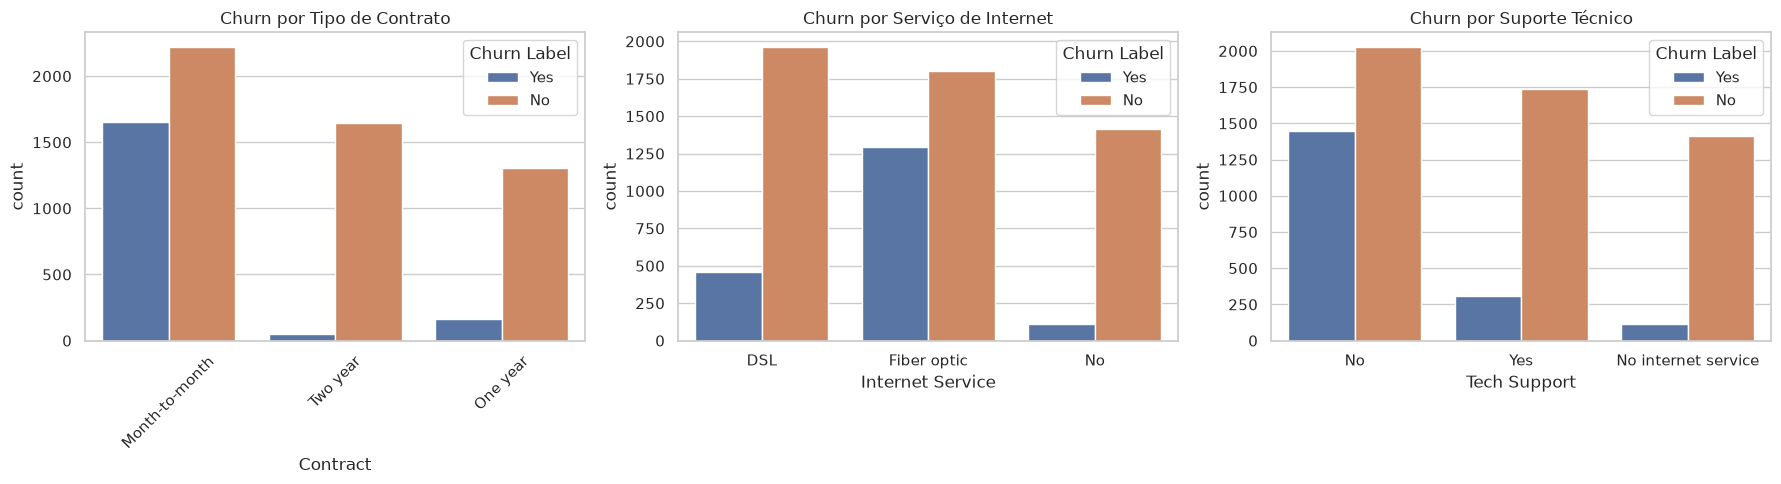

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Churn por Tipo de Contrato
sns.countplot(data=df, x='Contract', hue='Churn Label', ax=axes[0])
axes[0].set_title('Churn por Tipo de Contrato')
axes[0].tick_params(axis='x', rotation=45)

# 2. Churn por Tipo de Serviço de Internet
sns.countplot(data=df, x='Internet Service', hue='Churn Label', ax=axes[1])
axes[1].set_title('Churn por Serviço de Internet')

# 3. Churn por Oferta de Suporte Técnico
sns.countplot(data=df, x='Tech Support', hue='Churn Label', ax=axes[2])
axes[2].set_title('Churn por Suporte Técnico')

plt.tight_layout()
plt.show()


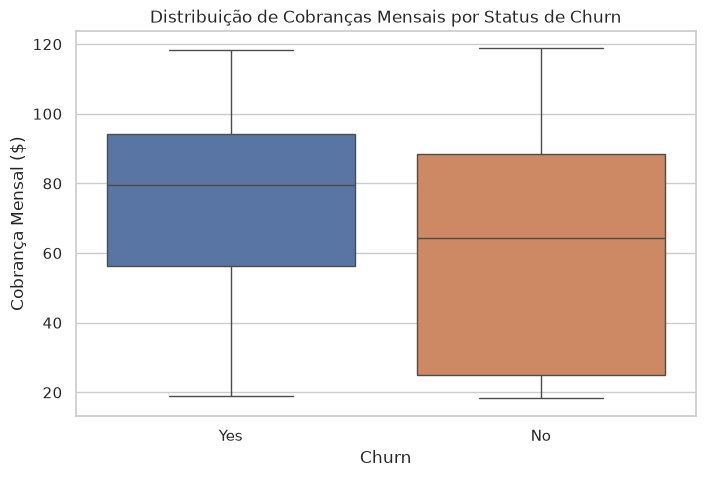

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn Label', y='Monthly Charges', hue='Churn Label', legend=False)
plt.title('Distribuição de Cobranças Mensais por Status de Churn')
plt.xlabel('Churn')
plt.ylabel('Cobrança Mensal ($)')
plt.show()


/tmp/ipykernel_203581/2572370228.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_reasons.values, y=churn_reasons.index, palette='Reds_r')


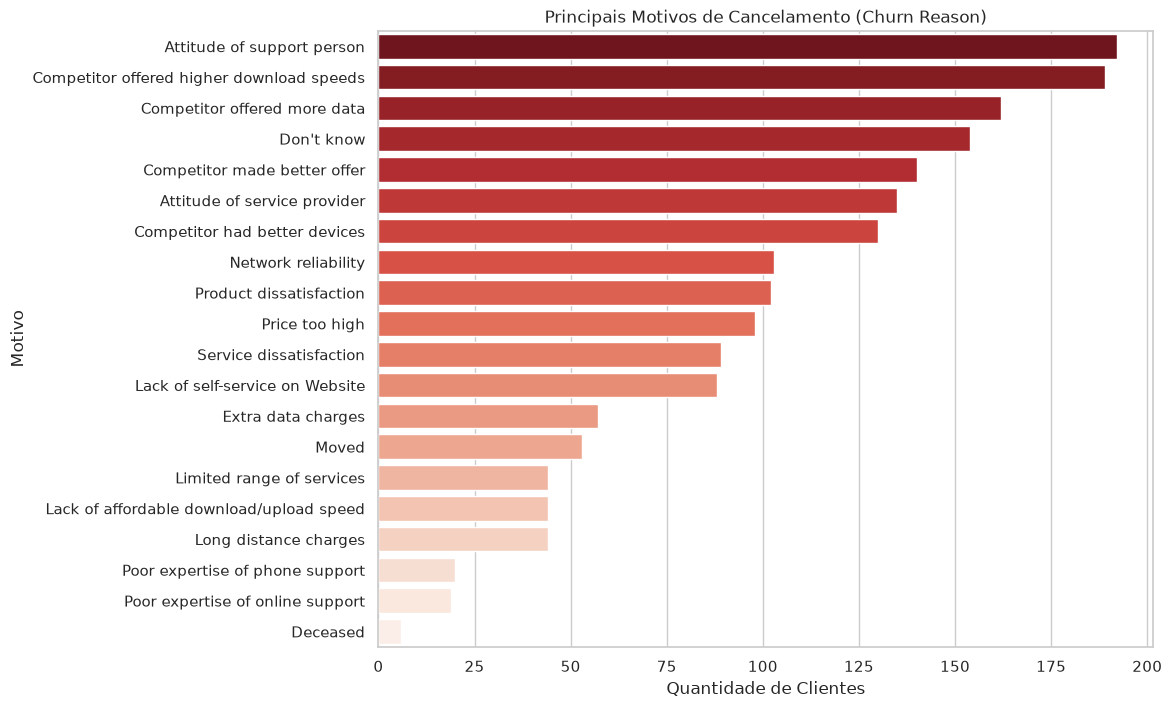

In [11]:
# Análise dos motivos de churn

# Célula para analisar os motivos de Churn
plt.figure(figsize=(10, 8))
# Filtrando apenas quem deu Churn e contando os motivos
churn_reasons = df[df['Churn Label'] == 'Yes']['Churn Reason'].value_counts()

sns.barplot(x=churn_reasons.values, y=churn_reasons.index, palette='Reds_r')
plt.title('Principais Motivos de Cancelamento (Churn Reason)')
plt.xlabel('Quantidade de Clientes')
plt.ylabel('Motivo')
plt.show()


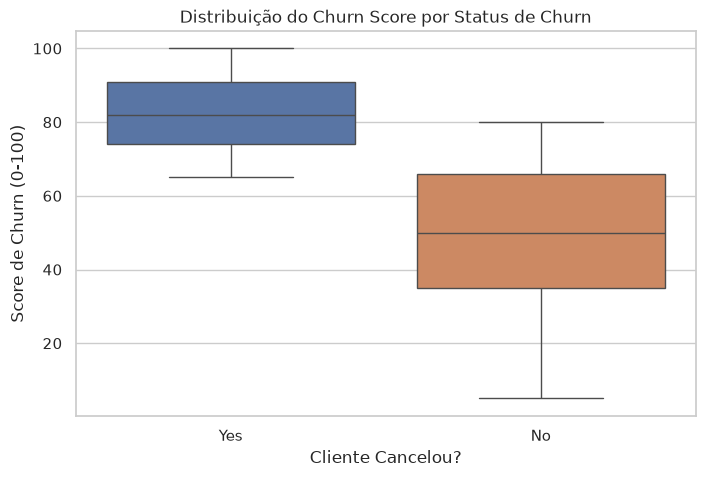

In [12]:
# Relação do score de churn com a saída real do cliente
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn Label', y='Churn Score', hue='Churn Label', legend=False)
plt.title('Distribuição do Churn Score por Status de Churn')
plt.xlabel('Cliente Cancelou?')
plt.ylabel('Score de Churn (0-100)')
plt.show()


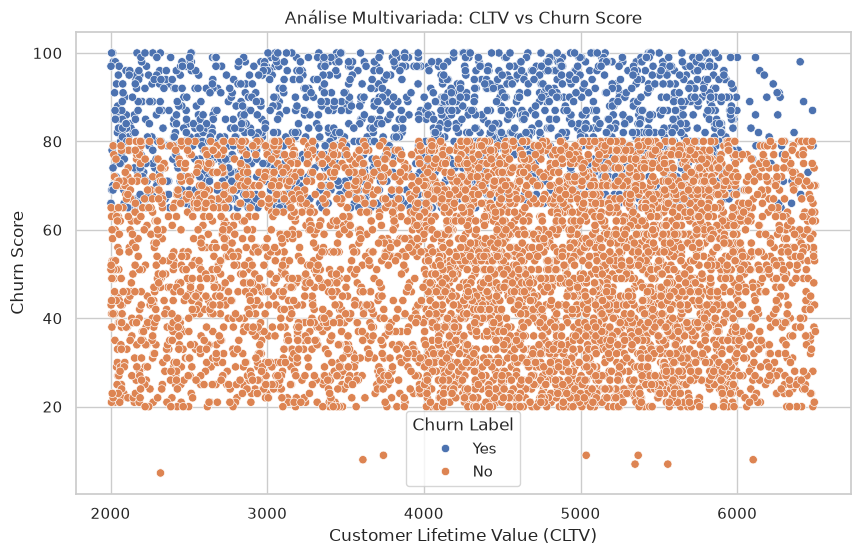

In [13]:
# Gráfico de dispersão para avaliar Valor do Cliente vs Risco de Saída
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='CLTV', y='Churn Score', hue='Churn Label')
plt.title('Análise Multivariada: CLTV vs Churn Score')
plt.xlabel('Customer Lifetime Value (CLTV)')
plt.ylabel('Churn Score')
plt.show()


Olhe para o eixo vertical (Churn Score). Existe uma linha divisória perfeita na pontuação 80:
• Acima de 80: Quase 100% dos pontos são azuis (Churn = Yes).
• Abaixo de 80: A esmagadora maioria dos pontos é laranja (Churn = No).

Em um cenário ideal, os pontos azuis deveriam se concentrar apenas no CLTV baixo (indicando que apenas clientes pequenos cancelam).
Como eles estão espalhados igualmente: O motivo que está fazendo os clientes cancelarem afeta a todos de forma igual, independente de quanto eles valem para a empresa. O problema pode ser de qualidade geral do serviço ou atendimento, e não puramente uma questão de faixa de preço.

/tmp/ipykernel_203581/2576683862.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


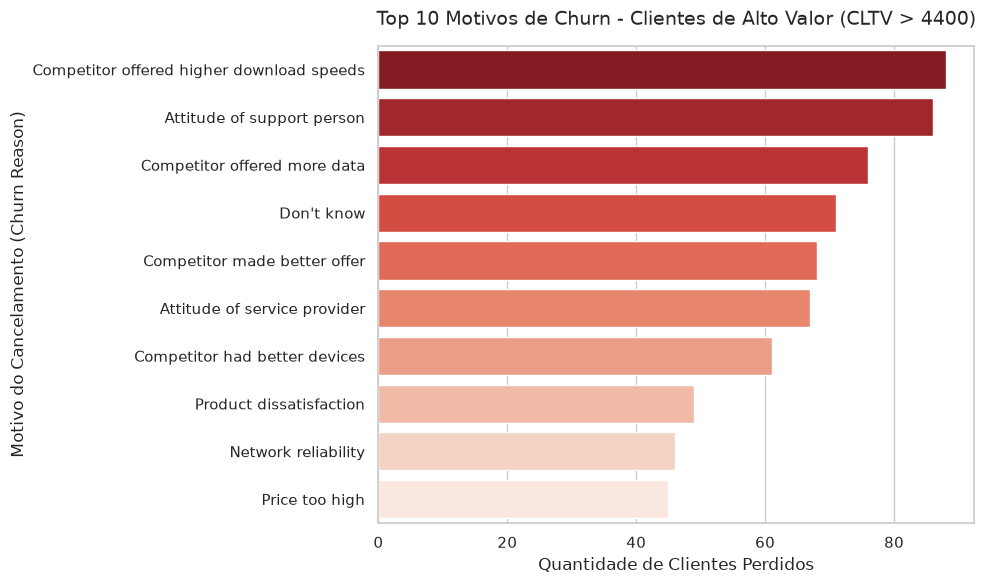

In [14]:
# 1. Definir o que é um "Cliente de Alto Valor" (usando a média do CLTV)
cltv_medio = df['CLTV'].mean()

# 2. Filtrar a base: Clientes que deram Churn E possuem CLTV acima da média
df_alto_valor_churn = df[(df['Churn Label'] == 'Yes') & (df['CLTV'] > cltv_medio)]

# 3. Contar a frequência dos motivos de cancelamento nesse grupo rico
motivos_alto_valor = df_alto_valor_churn['Churn Reason'].value_counts().head(10)

# 4. Plotar o gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(
    x=motivos_alto_valor.values, 
    y=motivos_alto_valor.index, 
    palette='Reds_r'
)

plt.title(f'Top 10 Motivos de Churn - Clientes de Alto Valor (CLTV > {cltv_medio:.0f})', fontsize=14, pad=15)
plt.xlabel('Quantidade de Clientes Perdidos')
plt.ylabel('Motivo do Cancelamento (Churn Reason)')
plt.tight_layout()
plt.show()


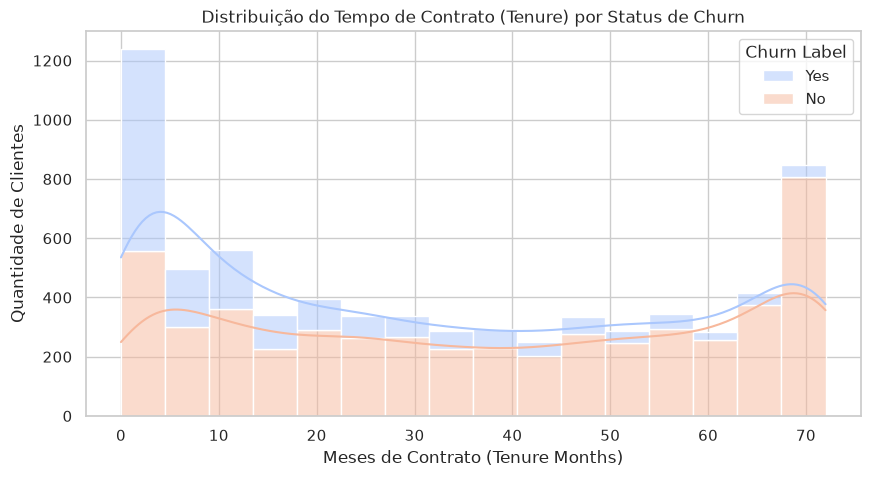

In [15]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Tenure Months', hue='Churn Label', multiple='stack', palette='coolwarm', kde=True)
plt.title('Distribuição do Tempo de Contrato (Tenure) por Status de Churn')
plt.xlabel('Meses de Contrato (Tenure Months)')
plt.ylabel('Quantidade de Clientes')
plt.show()


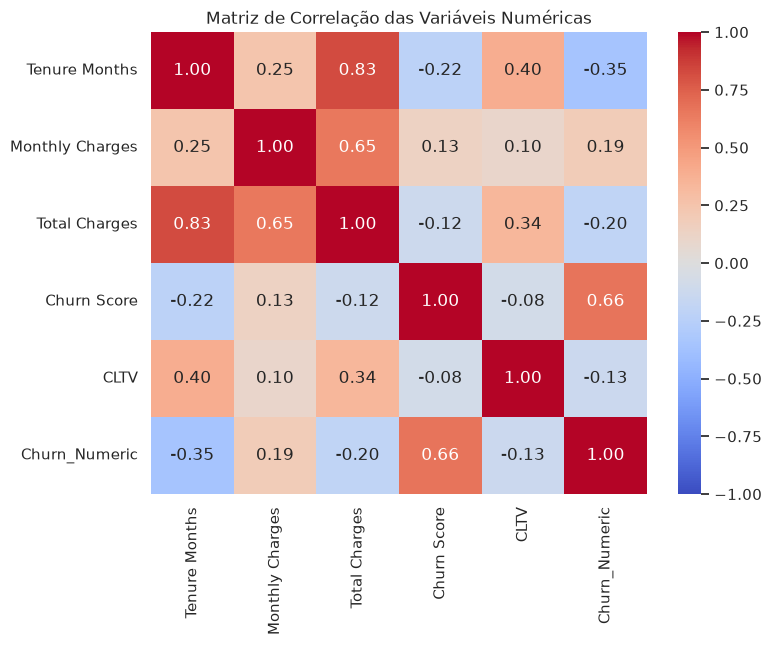

In [16]:
# 1. Cria uma cópia para não alterar o dataset original e transforma o Churn em binário
df_corr = df.copy()
df_corr['Churn_Numeric'] = df_corr['Churn Label'].map({'Yes': 1, 'No': 0})

# 2. Seleciona apenas as colunas numéricas mais importantes
colunas_numéricas = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Score', 'CLTV', 'Churn_Numeric']
matriz = df_corr[colunas_numéricas].corr()

# 3. Plota o Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(matriz, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação das Variáveis Numéricas')
plt.show()


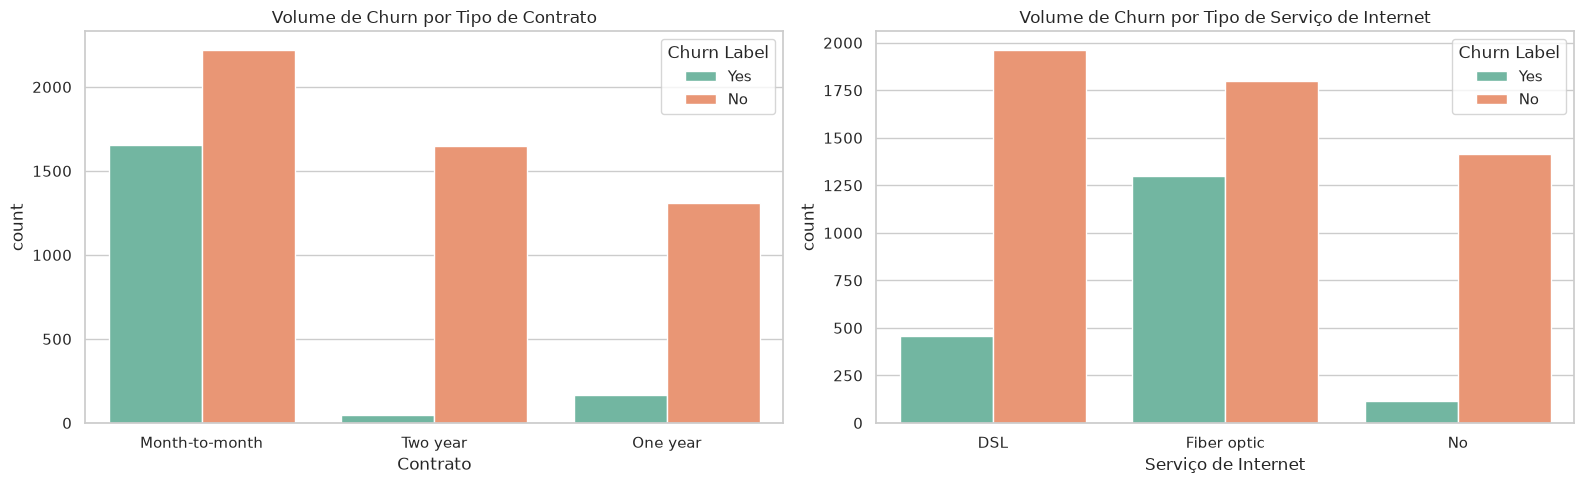

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Churn por Tipo de Contrato
sns.countplot(data=df, x='Contract', hue='Churn Label', ax=axes[0], palette='Set2')
axes[0].set_title('Volume de Churn por Tipo de Contrato')
axes[0].set_xlabel('Contrato')

# Gráfico 2: Churn por Tipo de Serviço de Internet
sns.countplot(data=df, x='Internet Service', hue='Churn Label', ax=axes[1], palette='Set2')
axes[1].set_title('Volume de Churn por Tipo de Serviço de Internet')
axes[1].set_xlabel('Serviço de Internet')

plt.tight_layout()
plt.show()


## Principais Insights da Análise
* **Contratos:** Clientes com contrato mensal (`Month-to-month`) têm uma propensão drasticamente maior ao churn comparados a contratos de longo prazo.
* **Tecnologia:** Clientes de Fibra Óptica apresentam alto volume de cancelamento, o que pode indicar problemas de qualidade ou preço nessa categoria.
* **Preço:** A mediana do valor da fatura mensal dos clientes que deram churn é visivelmente mais alta do que a dos clientes retidos.


-----------------------------------------------------------------------------------------------------------------------------------------------------

Regressão

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# =====================================================================
# 1. INGESTÃO DE DADOS E LIMPEZA ESTRUTURAL (DATA UNDERSTANDING)
# =====================================================================
DATA_PATH = Path("../data/raw/Telco_customer_churn.csv")
df = pd.read_csv(DATA_PATH, sep=";", decimal=",")

# Correção robusta de tipagem exigida pela base (GIGO Principle - Aula 2)
if 'Total Charges' in df.columns:
    df['Total Charges'] = pd.to_numeric(df['Total Charges'].astype(str).str.replace(',', '.'), errors='coerce')
    df['Total Charges'] = df['Total Charges'].fillna(0.0)

# =====================================================================
# 2. SEPARAÇÃO DO TARGET E TRATAMENTO DE DATA LEAKAGE
# =====================================================================
ALVO = 'Churn Label'

# Colunas que representam vazamento pós-evento (Devem ser removidas da inferência real)
colunas_vazamento = ['id', 'Customer ID', 'Churn Reason', 'Customer_ID', 'customerID', 'Churn Score', 'Churn Value', 'CLTV', ALVO]
colunas_preditoras = [col for col in df.columns if col not in colunas_vazamento]

X_raw = df[colunas_preditoras]
y = df[ALVO].replace({'Yes': 1, 'No': 0}).astype(int)

# Divisão controlada com Seed Fixo para Reprodutibilidade Científica (Exigência do Edital)
X_train, X_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, random_state=42)

# =====================================================================
# 3. CONSTRUÇÃO DO PIPELINE DE PRÉ-PROCESSAMENTO PRODUTIVO (CORRIGIDO)
# =====================================================================
num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        # Modelos lineares exigem normalização para convergência dos pesos
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)
# Encapamento do Baseline completo (Pré-processador + Algoritmo Linear)
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# =====================================================================
# 4. TREINAMENTO E EXTRAÇÃO DE MÉTRICAS DO COMPROMISSO VIÉS-VARIÂNCIA
# =====================================================================
# Treina a esteira inteira de uma só vez (Aprende transformações estritamente na base de Treino)
baseline_pipeline.fit(X_train, y_train)

# Predição no conjunto de holdout (inédito)
y_pred = baseline_pipeline.predict(X_test)

print("============ RESULTADOS DO MODELO BASELINE PADRONIZADO ============")
print(f"Acurácia de Teste: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão de Teste: {precision_score(y_test, y_pred):.4f}")
print(f"Recall de Teste:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score de Teste:  {f1_score(y_test, y_pred):.4f}")
print("===================================================================")


/tmp/ipykernel_203581/1222682754.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()


============ RESULTADOS DO MODELO BASELINE PADRONIZADO ============
Acurácia de Teste: 0.7956
Precisão de Teste: 0.6667
Recall de Teste:    0.5600
F1-Score de Teste:  0.6087


### 🎯 Definição e Justificativa das Métricas do Projeto

*   **Métrica de Negócio:** O indicador-chave de sucesso (KPI) para a diretoria da telecom é o **Churn Rate Mensal** e a **Receita Recorrente Retida**. O objetivo prático é reduzir o cancelamento de clientes em 15% por meio de ofertas preventivas de fidelização.
*   **Métrica Técnica Escolhida (F1-Score):** Para avaliar o modelo, escolhemos o **F1-Score** como métrica primária em detrimento da Acurácia isolada. 
    *   *Por que não usar apenas a Acurácia?* Como a base apresenta um desbalanceamento natural (mais clientes ativos do que cancelados), um modelo que simplesmente chutasse "Não cancela" teria uma acurácia alta, mas seria inútil para o negócio.
    *   *O Equilíbrio do F1-Score:* O F1-Score calcula a média harmônica entre a **Precisão** (garante que não daremos descontos caros para clientes que não iam cancelar) e o **Recall** (garante que mapeamos a maior quantidade possível de clientes em risco real antes que eles saiam). O nosso baseline estabeleceu um **F1-Score inicial de 0.6093**, que servirá como alvo de melhoria para os próximos modelos.